#  Import ও data load

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

DATA_PATH = "../data/"
OUTPUT_PATH = "../outputs/results/"
MODEL_PATH = "../outputs/models/"

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

wallets_features = pd.read_csv(DATA_PATH + "wallets_features.csv")
wallets_classes = pd.read_csv(DATA_PATH + "wallets_classes.csv")

addr_addr = pd.read_csv(DATA_PATH + "AddrAddr_edgelist.csv")

print("Data loaded successfully.")
print("Wallet features:", wallets_features.shape)
print("Wallet classes:", wallets_classes.shape)
print("Addr-Addr edges:", addr_addr.shape)

Data loaded successfully.
Wallet features: (1268260, 57)
Wallet classes: (822942, 2)
Addr-Addr edges: (2868964, 2)


# Edge column

In [2]:
print("Original edge columns:")
print(addr_addr.columns.tolist())

addr_addr.columns = ["source", "target"]

print("\nRenamed edge columns:")
print(addr_addr.columns.tolist())

addr_addr.head()

Original edge columns:
['input_address', 'output_address']

Renamed edge columns:
['source', 'target']


,source,target
0,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,1GASxu5nMntiRKdVtTVRvEbP965G51bhHH
1,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a
2,13Lhad3SAmu2vqYg2dxbNcxH7LE77kJu2w,1GFdrdgtG34GChM8SMpMwcXFc4nYbH1A5G
3,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,19q57SeCEzTnWrWVXA43nZzhSiXkYggh7c
4,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,1Kk1NVYnCE8ALXDhgMM6HqTt1jDSvi6QBA


# Duplicate edge- to weight

In [3]:
print("Original edges:", len(addr_addr))

addr_addr_weighted = (
    addr_addr
    .groupby(["source", "target"])
    .size()
    .reset_index(name="weight")
    .sort_values("weight", ascending=False)
    .reset_index(drop=True)
)

print("Unique directed wallet pairs:", len(addr_addr_weighted))
addr_addr_weighted.head()

Original edges: 2868964
Unique directed wallet pairs: 2784344


,source,target,weight
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,1453
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,1245
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,851
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,847
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,639


# Directed wallet graph

In [4]:

G = nx.from_pandas_edgelist(
    addr_addr_weighted,
    source="source",
    target="target",
    edge_attr="weight",
    create_using=nx.DiGraph()
)

print("Graph created successfully.")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Graph type:", type(G).__name__)

Graph created successfully.
Number of nodes: 822942
Number of edges: 2784344
Graph type: DiGraph


#  graph statistics


In [5]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

density = nx.density(G)

print(f"Nodes: {num_nodes:,}")
print(f"Edges: {num_edges:,}")
print(f"Graph density: {density:.8f}")

Nodes: 822,942
Edges: 2,784,344
Graph density: 0.00000411


# Degree features

In [6]:
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())
total_degree = dict(G.degree())

degree_df = pd.DataFrame({
    "address": list(G.nodes()),
    "in_degree": [in_degree[node] for node in G.nodes()],
    "out_degree": [out_degree[node] for node in G.nodes()],
    "total_degree": [total_degree[node] for node in G.nodes()]
})

degree_df.head()

,address,in_degree,out_degree,total_degree
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,2198,1370,3568
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,3,1183,1186
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,210,782,992
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,7,828,835
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,1,575,576


<!-- in_degree = কতগুলো wallet থেকে টাকা এসেছে

out_degree = কতগুলো wallet-এ টাকা পাঠানো হয়েছে

total_degree = মোট connection -->

# Degree distribution

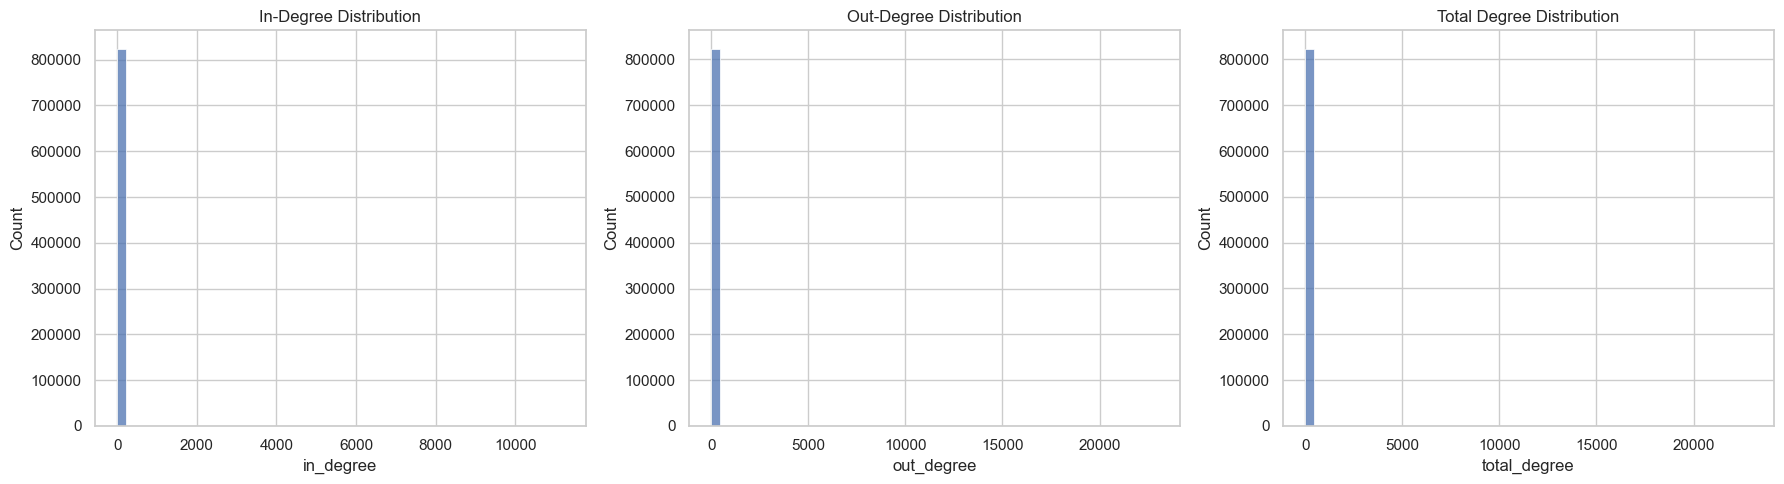

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(degree_df["in_degree"], bins=50, ax=axes[0])
axes[0].set_title("In-Degree Distribution")

sns.histplot(degree_df["out_degree"], bins=50, ax=axes[1])
axes[1].set_title("Out-Degree Distribution")

sns.histplot(degree_df["total_degree"], bins=50, ax=axes[2])
axes[2].set_title("Total Degree Distribution")

plt.tight_layout()
plt.show()

# Edge weight analysis

Weight statistics:
count    2.784344e+06
mean     1.030391e+00
std      1.950814e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.453000e+03
Name: weight, dtype: float64


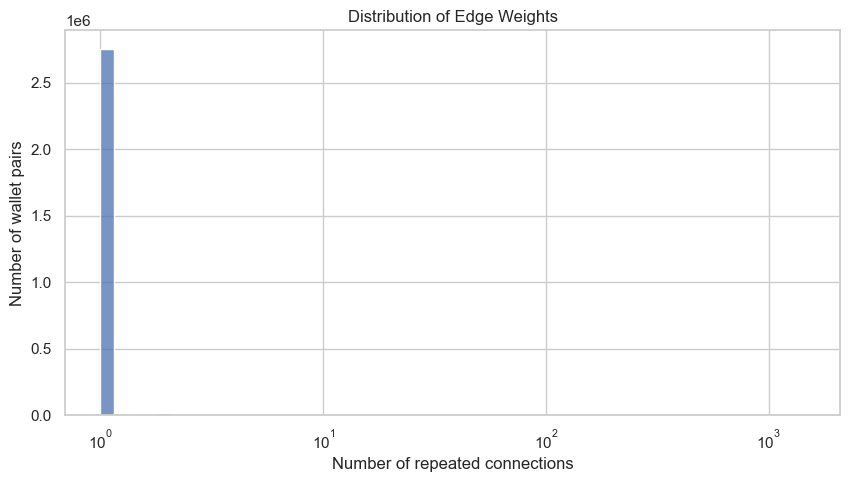

In [8]:
print("Weight statistics:")
print(addr_addr_weighted["weight"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(
    addr_addr_weighted["weight"],
    bins=50,
    log_scale=True
)
plt.title("Distribution of Edge Weights")
plt.xlabel("Number of repeated connections")
plt.ylabel("Number of wallet pairs")
plt.show()

# Degree centrality

In [9]:
degree_centrality = nx.degree_centrality(G)

degree_df["degree_centrality"] = degree_df["address"].map(degree_centrality)

degree_df.sort_values(
    by="degree_centrality",
    ascending=False
).head(10)

,address,in_degree,out_degree,total_degree,degree_centrality
904,1GX28yLjVWux7ws4UQ9FB4MnLH4UKTPK2z,1,22995,22996,0.027944
76,1N52wHoVR79PMDishab2XmRHsbekCdGquK,11214,3075,14289,0.017363
10,17A16QmavnUfCW11DAApiJxp7ARnxN5pGX,81,12317,12398,0.015065
387,33uVuTnQyaCTeK8MwZdaxgLNJCECwvxZQE,4,8853,8857,0.010763
3063,38DPYmsa7RXwLrhpTP6udrfSiGn5dzdGAC,1,8705,8706,0.010579
1514,18WYMeJ4cxoeb7LxWHMxayuJGVBWfGjckD,22,5910,5932,0.007208
467501,1DTq88861GuHswQdzaxREBemWt6A4UX4ot,0,5508,5508,0.006693
156,12cgpFdJViXbwHbhrA3TuW1EGnL25Zqc3P,3778,1705,5483,0.006663
11672,3QuHejbAAbeRoTkH5wBwGzMipf4R3zpQga,5019,0,5019,0.006099
434,1FAv42GaDuQixSzEzSbx6aP1Kf4WVWpQUY,4045,833,4878,0.005928


# Top connected wallets

In [10]:
top_in_degree = degree_df.sort_values(
    by="in_degree",
    ascending=False
).head(10)

top_out_degree = degree_df.sort_values(
    by="out_degree",
    ascending=False
).head(10)

print("Top 10 wallets by incoming connections:")
display(top_in_degree)

print("\nTop 10 wallets by outgoing connections:")
display(top_out_degree)

Top 10 wallets by incoming connections:


,address,in_degree,out_degree,total_degree,degree_centrality
76,1N52wHoVR79PMDishab2XmRHsbekCdGquK,11214,3075,14289,0.017363
11672,3QuHejbAAbeRoTkH5wBwGzMipf4R3zpQga,5019,0,5019,0.006099
434,1FAv42GaDuQixSzEzSbx6aP1Kf4WVWpQUY,4045,833,4878,0.005928
156,12cgpFdJViXbwHbhrA3TuW1EGnL25Zqc3P,3778,1705,5483,0.006663
622,17Akhagbr3iz9jZQDPgNmr1kkRW3NNf8EW,3577,135,3712,0.004511
819,1Y2sKhUZvsP2EANpKra3FaFZufHq5VEwT,2913,160,3073,0.003734
3211,1KjnLgQDf2X4YPVFSAYFVCXDuuM6yfymYv,2346,89,2435,0.002959
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,2198,1370,3568,0.004336
4947,1D12giTaEK9zVePUX9d5R5boQJpGZeLet,2066,70,2136,0.002596
10899,1FvtWwP3ePJDeR6K7ZePGujUuusUTds8Vy,1996,2,1998,0.002428



Top 10 wallets by outgoing connections:


,address,in_degree,out_degree,total_degree,degree_centrality
904,1GX28yLjVWux7ws4UQ9FB4MnLH4UKTPK2z,1,22995,22996,0.027944
10,17A16QmavnUfCW11DAApiJxp7ARnxN5pGX,81,12317,12398,0.015065
387,33uVuTnQyaCTeK8MwZdaxgLNJCECwvxZQE,4,8853,8857,0.010763
3063,38DPYmsa7RXwLrhpTP6udrfSiGn5dzdGAC,1,8705,8706,0.010579
1514,18WYMeJ4cxoeb7LxWHMxayuJGVBWfGjckD,22,5910,5932,0.007208
467501,1DTq88861GuHswQdzaxREBemWt6A4UX4ot,0,5508,5508,0.006693
591,3QGJ8o2oMWBBFfd6yBLqLd5RArSK5Ep84g,103,4518,4621,0.005615
13462,16FR5fRAZJ4u3rxDfCJ28hntcFiNtiq9fW,0,4506,4506,0.005475
24646,3GmjTdhoMaCrPUTMEgzbFYkVt4B5JMYL6w,1,4389,4390,0.005335
17361,1JWJT1pHyEgxmCZrrwVxDwdrTVFfiLWVwc,2,4031,4033,0.004901


# Neighbor-based features

In [11]:
neighbor_features = []

for node in G.nodes():
    predecessors = list(G.predecessors(node))
    successors = list(G.successors(node))

    neighbor_features.append({
        "address": node,
        "num_predecessors": len(predecessors),
        "num_successors": len(successors),
        "num_neighbors": len(set(predecessors + successors))
    })

neighbor_df = pd.DataFrame(neighbor_features)

print("Neighbor features created.")
neighbor_df.head()

Neighbor features created.


,address,num_predecessors,num_successors,num_neighbors
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,2198,1370,3553
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,3,1183,1185
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,210,782,991
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,7,828,834
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,1,575,575


# Graph features merge

In [12]:
graph_features = degree_df.merge(
    neighbor_df,
    on="address",
    how="left"
)

print("Graph feature dataset shape:", graph_features.shape)
graph_features.head()

Graph feature dataset shape: (822942, 8)


,address,in_degree,out_degree,total_degree,degree_centrality,num_predecessors,num_successors,num_neighbors
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,2198,1370,3568,0.004336,2198,1370,3553
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,3,1183,1186,0.001441,3,1183,1185
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,210,782,992,0.001205,210,782,991
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,7,828,835,0.001015,7,828,834
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,1,575,576,0.000700,1,575,575


# Labels merge

In [13]:
graph_labeled = graph_features.merge(
    wallets_classes,
    on="address",
    how="left"
)

print("Labeled graph dataset shape:", graph_labeled.shape)
graph_labeled["class"].value_counts()

Labeled graph dataset shape: (822942, 9)


class
3    557588
2    251088
1     14266
Name: count, dtype: int64

# Class-wise graph feature comparison

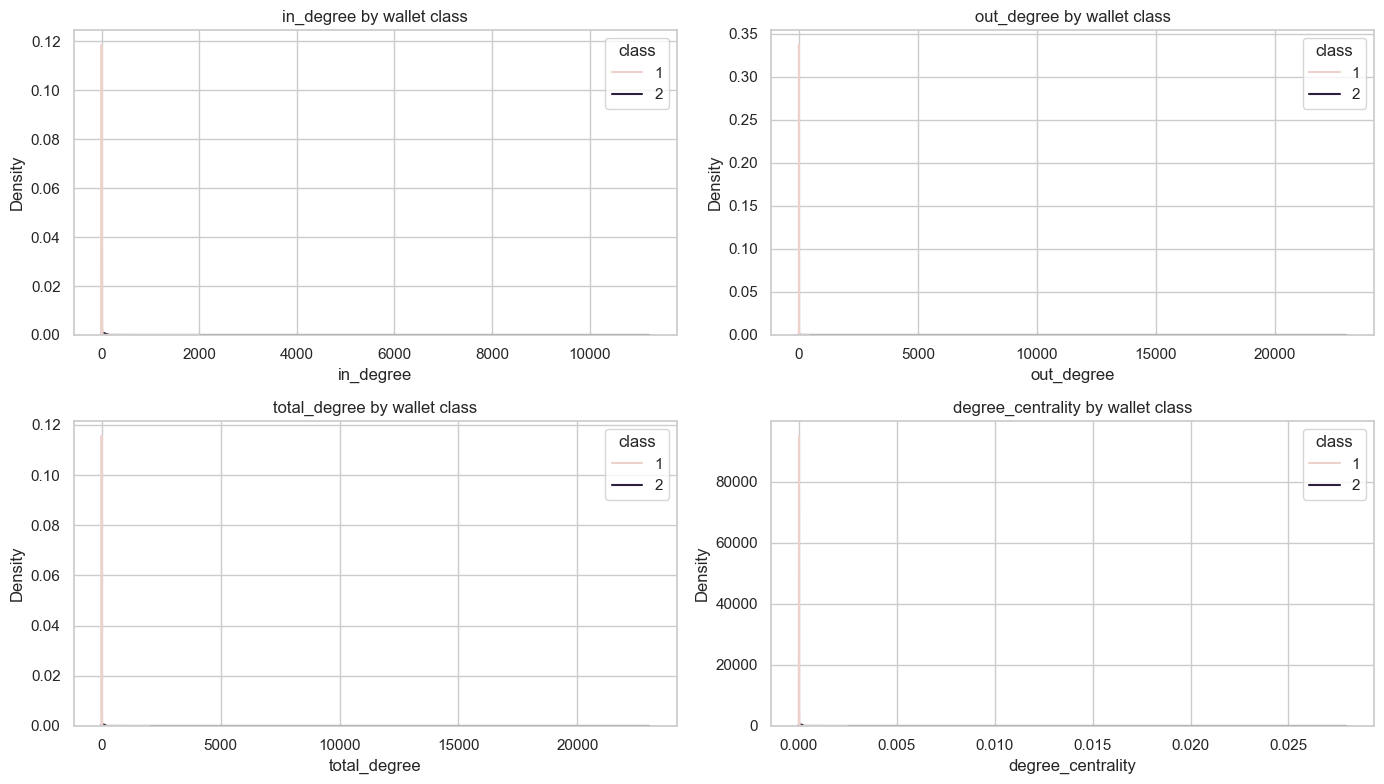

In [14]:
labeled_graph = graph_labeled[
    graph_labeled["class"].isin([1, 2])
].copy()

graph_cols = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_centrality"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, col in enumerate(graph_cols):
    row, col_pos = divmod(i, 2)

    sns.kdeplot(
        data=labeled_graph,
        x=col,
        hue="class",
        common_norm=False,
        ax=axes[row, col_pos]
    )

    axes[row, col_pos].set_title(f"{col} by wallet class")

plt.tight_layout()
plt.show()

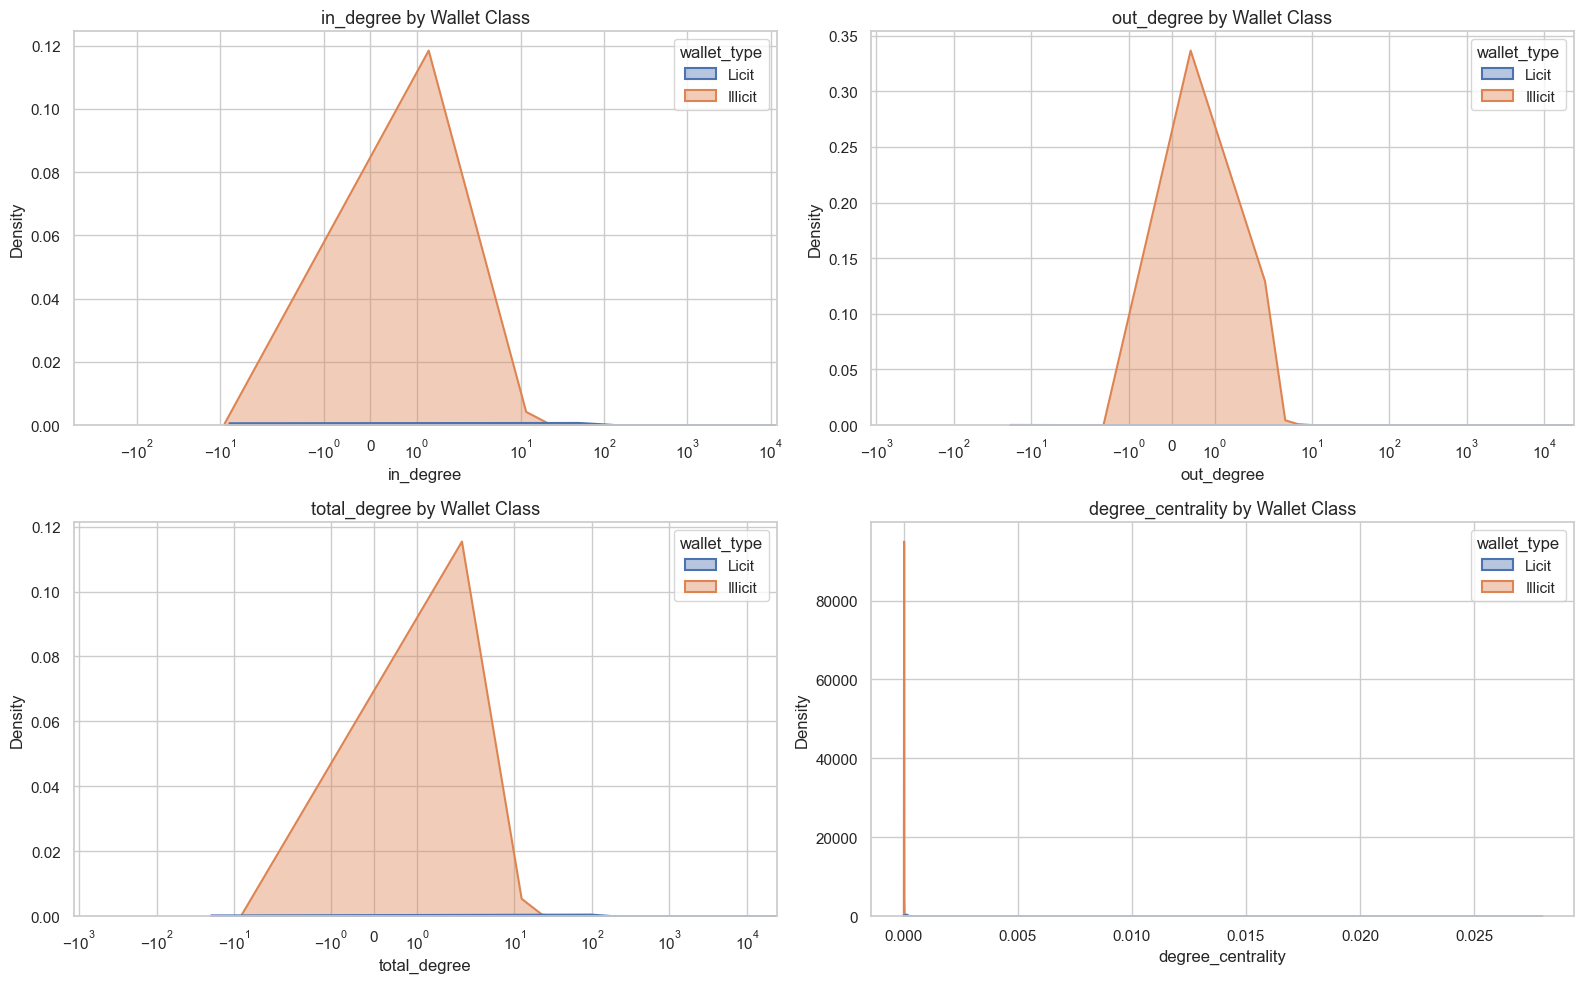

In [15]:
labeled_graph = graph_labeled[
    graph_labeled["class"].isin([1, 2])
].copy()

graph_cols = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_centrality"
]

class_labels = {
    1: "Illicit",
    2: "Licit"
}

labeled_graph["wallet_type"] = labeled_graph["class"].map(class_labels)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for i, col in enumerate(graph_cols):
    row, col_pos = divmod(i, 2)
    ax = axes[row, col_pos]

    sns.kdeplot(
        data=labeled_graph,
        x=col,
        hue="wallet_type",
        common_norm=False,
        fill=True,
        alpha=0.4,
        linewidth=1.5,
        ax=ax
    )

    ax.set_title(f"{col} by Wallet Class", fontsize=13)
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

    if col != "degree_centrality":
        ax.set_xscale("symlog")

plt.tight_layout()
plt.show()

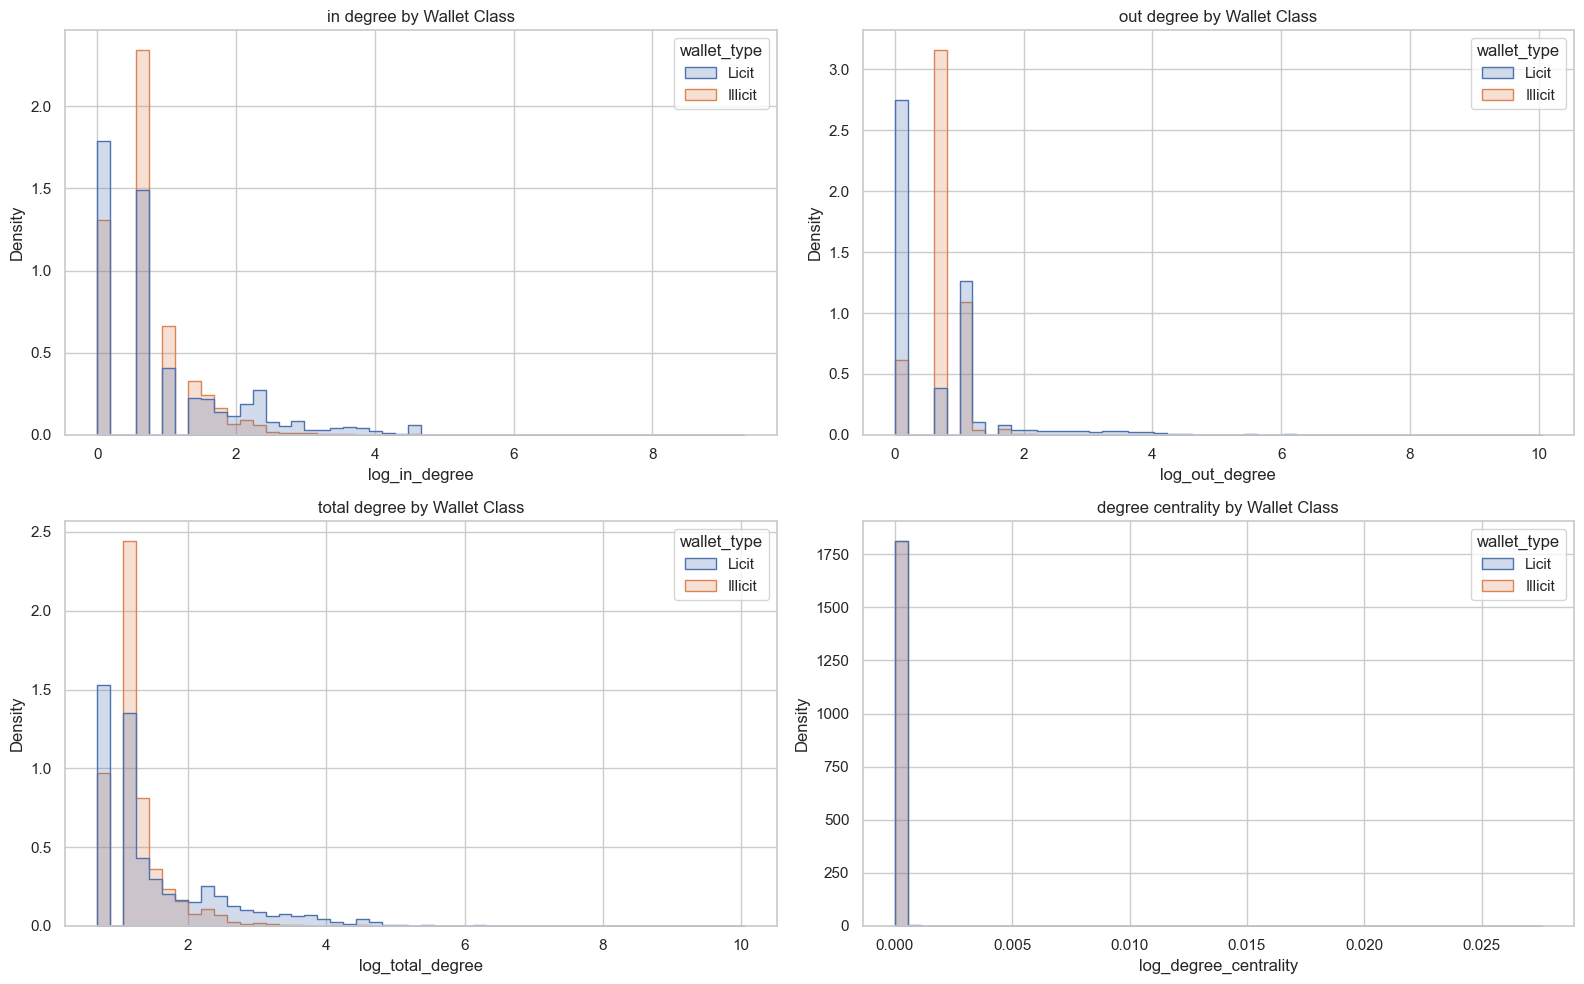

In [18]:
plot_df = labeled_graph.copy()

for col in ["in_degree", "out_degree", "total_degree"]:
    plot_df[f"log_{col}"] = np.log1p(plot_df[col])

plot_df["log_degree_centrality"] = np.log1p(plot_df["degree_centrality"])

log_cols = [
    "log_in_degree",
    "log_out_degree",
    "log_total_degree",
    "log_degree_centrality"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for i, col in enumerate(log_cols):
    row, col_pos = divmod(i, 2)
    ax = axes[row, col_pos]

    sns.histplot(
        data=plot_df,
        x=col,
        hue="wallet_type",
        element="step",
        stat="density",
        common_norm=False,
        bins=50,
        ax=ax
    )

    ax.set_title(f"{col.replace('log_', '').replace('_', ' ')} by Wallet Class")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

# Graph feature save

In [16]:
graph_features.to_csv(
    OUTPUT_PATH + "wallet_graph_features.csv",
    index=False
)

graph_labeled.to_csv(
    OUTPUT_PATH + "wallet_graph_features_with_labels.csv",
    index=False
)

addr_addr_weighted.to_csv(
    OUTPUT_PATH + "addr_addr_weighted_edges.csv",
    index=False
)

print("Graph-building outputs saved successfully.")
print(OUTPUT_PATH + "wallet_graph_features.csv")
print(OUTPUT_PATH + "wallet_graph_features_with_labels.csv")
print(OUTPUT_PATH + "addr_addr_weighted_edges.csv")

Graph-building outputs saved successfully.
../outputs/results/wallet_graph_features.csv
../outputs/results/wallet_graph_features_with_labels.csv
../outputs/results/addr_addr_weighted_edges.csv


# Summary

In [17]:
summary = {
    "total_wallets_in_graph": G.number_of_nodes(),
    "total_unique_edges": G.number_of_edges(),
    "original_edges": len(addr_addr),
    "weighted_edges": len(addr_addr_weighted),
    "graph_density": nx.density(G),
    "max_in_degree": degree_df["in_degree"].max(),
    "max_out_degree": degree_df["out_degree"].max(),
    "max_total_degree": degree_df["total_degree"].max()
}

summary_df = pd.DataFrame([summary])
summary_df

,total_wallets_in_graph,total_unique_edges,original_edges,weighted_edges,graph_density,max_in_degree,max_out_degree,max_total_degree
0,822942,2784344,2868964,2784344,0.000004,11214,22995,22996
